# Análisis y procesamiento de datos

En este cuaderno veremos un ejemplo de exploración de datos con Python. Analizar los datasets es una tarea esencial en cualquier problema de aprendizaje automático, pues ayuda a mejorar la calidad de la información y potencialmente al rendimiento de los algoritmos.

In [1]:
# Importamos los paquetes necesarios
import pandas as pd #excel, tablas
import numpy as np #mates y matrices
import matplotlib.pyplot as plt #graficos
import sklearn.preprocessing as prep #ML
%matplotlib inline

Para este ejemplo vamos a utilizar datos extraídos de [OpenML](https://www.openml.org/), una plataforma con multitud de datasets gratuitos. El conjunto de datos contiene información sobre 500 alumnos de un colegio de Irlanda, y si realizaron posteriormente el examen de acceso a la universidad.

In [ ]:
#limpiar cache
from sklearn.datasets import clear_data_home
clear_data_home()

In [2]:
# Cargamos los datos
from sklearn.datasets import fetch_openml

data = fetch_openml(name='irish')
 #(data_id=217)
#(name = 'irish')
 #
 #
data, target = data['data'], data['target']

La variable `data` contiene el conjunto de datos, y `target` la variable a predecir (clasificación binaria). En este cuaderno nos centraremos principalmente en entender los datos, sin hacer aún ninguno modelo predictivo.

In [3]:
data.sample(10)

,Sex,DVRT,Educational_level,Prestige_score,Type_school
8,male,92,Junior_cycle_terminal_leaver-vocational_school,33.0,vocational
396,female,104,Senior_cycle_incomplete-vocational_school,37.0,vocational
467,male,121,Senior_cycle_terminal_leaver-secondary_school,37.0,secondary
11,male,84,Junior_cycle_terminal_leaver-vocational_school,18.0,vocational
66,male,117,Senior_cycle_terminal_leaver-secondary_school,NaN,secondary
267,male,70,Primary_terminal_leaver,31.0,primary_terminal_leaver
148,male,126,Junior_cycle_incomplete-vocational_school,61.0,vocational
117,female,101,Junior_cycle_terminal_leaver-secondary_school,38.0,secondary
483,female,127,Senior_cycle_terminal_leaver-secondary_school,58.0,secondary
92,female,108,Senior_cycle_terminal_leaver-secondary_school,27.0,secondary


## 1. Información general de los datos

En primer lugar veamos qué información contiene el conjunto de datos: el tamaño, qué tipos de variables, si hay registros nulos, etc.

In [ ]:
# Filas y columnas
data.shape

(500, 5)

In [ ]:
# Información general del dataframe
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Sex                500 non-null    category
 1   DVRT               500 non-null    int64   
 2   Educational_level  494 non-null    category
 3   Prestige_score     474 non-null    float64 
 4   Type_school        500 non-null    category
dtypes: category(3), float64(1), int64(1)
memory usage: 10.0 KB


In [6]:
# Estadística general de las variables
data.describe(include = 'all')

,Sex,DVRT,Educational_level,Prestige_score,Type_school
count,500,500.000000,494,474.000000,500
unique,2,NaN,10,NaN,3
top,female,NaN,Senior_cycle_terminal_leaver-secondary_school,NaN,secondary
freq,250,NaN,158,NaN,325
mean,NaN,100.152000,NaN,38.934599,NaN
std,NaN,15.456348,NaN,15.333707,NaN
min,NaN,65.000000,NaN,18.000000,NaN
25%,NaN,90.000000,NaN,28.000000,NaN
50%,NaN,101.000000,NaN,37.000000,NaN
75%,NaN,111.000000,NaN,46.000000,NaN


La tabla contiene 500 filas y 5 columnas: dos de tipo numérico (`DVRT` y `Prestige_Score`) y tres de tipo categórico. También podemos ver los valores medios o la moda de las columnas en la celda anterior.

## 2. Análisis de la información

A continuación vamos a tratar de entender mejor los datos, entendiendo la relación entre las columnas y el target.

Por comodidad, vamos a crear una columna con la variable target en el conjunto de datos.

In [7]:
data['target'] = target
data.head()

,Sex,DVRT,Educational_level,Prestige_score,Type_school,target
0,male,113,Junior_cycle_incomplete-secondary_school,28.0,secondary,not_taken
1,male,101,Primary_terminal_leaver,28.0,primary_terminal_leaver,not_taken
2,male,110,Senior_cycle_terminal_leaver-secondary_school,69.0,secondary,taken
3,male,121,Junior_cycle_terminal_leaver-secondary_school,57.0,secondary,not_taken
4,male,82,Junior_cycle_terminal_leaver-vocational_school,18.0,vocational,not_taken


In [8]:
# Veamos los valores de las variables categóricas
for col in ['Sex', 'Educational_level', 'Type_school', 'target']:
    print(data[col].value_counts())
    print('')

Sex
female    250
male      250
Name: count, dtype: int64

Educational_level
Senior_cycle_terminal_leaver-secondary_school     158
Junior_cycle_terminal_leaver-vocational_school     68
Junior_cycle_terminal_leaver-secondary_school      65
3rd_level_complete                                 57
Junior_cycle_incomplete-vocational_school          50
Primary_terminal_leaver                            37
Junior_cycle_incomplete-secondary_school           30
Senior_cycle_incomplete-vocational_school          13
Senior_cycle_incomplete-secondary_school            9
3rd_level_incomplete                                7
Name: count, dtype: int64

Type_school
secondary                  325
vocational                 138
primary_terminal_leaver     37
Name: count, dtype: int64

target
not_taken    278
taken        222
Name: count, dtype: int64



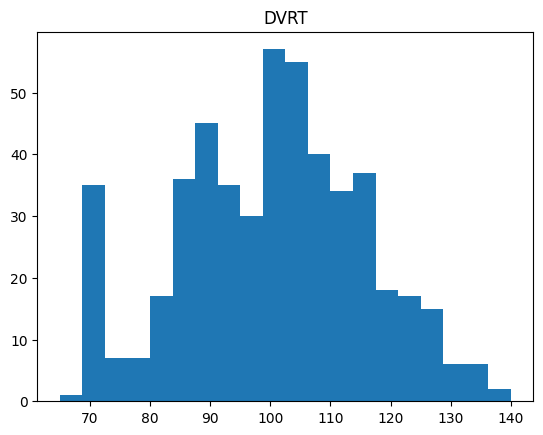

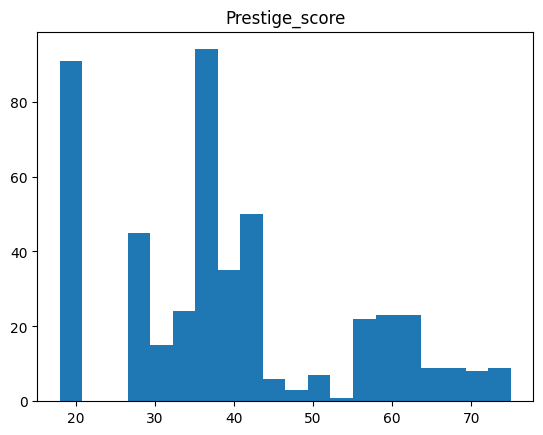

In [9]:
# Distribución de las variables numéricas
for col in ['DVRT', 'Prestige_score']:
    plt.hist(data[col], bins = 20)
    plt.title(col)
    plt.show()
    plt.close()

<Axes: xlabel='DVRT', ylabel='Prestige_score'>

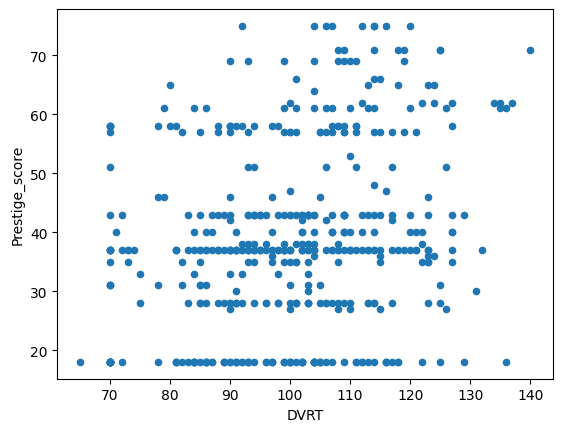

In [10]:
# Relación entre estas dos variables
data.plot(x = 'DVRT', y = 'Prestige_score', kind = 'scatter')

Ahora vamos a transformar la variable target en una columna numérica: 1 si ha realizado el examen, 0 en caso contrario.

In [11]:
# Transformación de la variable target
data['target_num'] = data.target.apply(lambda r: 1 if r == 'taken' else 0).astype('float64')
data.head()

,Sex,DVRT,Educational_level,Prestige_score,Type_school,target,target_num
0,male,113,Junior_cycle_incomplete-secondary_school,28.0,secondary,not_taken,0.0
1,male,101,Primary_terminal_leaver,28.0,primary_terminal_leaver,not_taken,0.0
2,male,110,Senior_cycle_terminal_leaver-secondary_school,69.0,secondary,taken,1.0
3,male,121,Junior_cycle_terminal_leaver-secondary_school,57.0,secondary,not_taken,0.0
4,male,82,Junior_cycle_terminal_leaver-vocational_school,18.0,vocational,not_taken,0.0


**Ejercicio**: Calcular el porcentaje de alumnos que han realizado el examen en función del sexo y el tipo de escuela.

In [12]:
## Escribir código aquí ##
porcentajes = (
    data.groupby(['Sex', 'Type_school'])['target_num']
        .agg(['mean', 'count'])
        .rename(columns={'mean': 'percentage_taken'})
)

# Convertir a porcentaje
porcentajes['percentage_taken'] = porcentajes['percentage_taken'] * 100

porcentajes

/tmp/ipython-input-1463049051.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(['Sex', 'Type_school'])['target_num']


percentage_taken  count
Sex    Type_school                                     
female primary_terminal_leaver          0.000000     17
       secondary                       62.430939    181
       vocational                       5.769231     52
male   primary_terminal_leaver          0.000000     20
       secondary                       70.833333    144
       vocational                       4.651163     86

Para finalizar el análisis de estos datos, comprobemos la correlación entre la variable objetivo y las variables numéricas.

In [ ]:
data.select_dtypes(include = 'number').corr()#m.correlacion

,DVRT,Prestige_score,target_num
DVRT,1.000000,0.258157,0.413265
Prestige_score,0.258157,1.000000,0.318096
target_num,0.413265,0.318096,1.000000


## 3. Preprocesamiento del dataset

Ahora que hemos construido una intuición sobre la información que disponemos, vamos a transformar los datos de forma que puedan utilizarse en un modelo de aprendizaje automático.

### a) Imputación de valores nulos

Hemos comprobado que existen dos variables que tienen valores nulos: `Educational_levell` y `Prestige_score`. Vamos a imputar estos missings con el valor más común y con el valor medio respectivamente.

In [ ]:
# Imputación Educational_level con el valor más común
top_value = data.Educational_level.value_counts().index[0]
data['Educational_level'] = data['Educational_level'].fillna(top_value)

In [ ]:
# Imputación Prestige_score con la media
mean_value = data.Prestige_score.mean()
data['Prestige_score'] = data['Prestige_score'].fillna(mean_value)

In [ ]:
# Comprobamos que no hay más nulos
data.isna().sum()

,0
Sex,0
DVRT,0
Educational_level,0
Prestige_score,0
Type_school,0
target,0
target_num,0


### b) Transformación de variables categóricas

Tras ello, vamos a transformar las variables categóricas en columnas one-hot o *dummy*.

Para el caso de la columna `Sex` es inmediato, pues es binaria.

In [ ]:
data['Sex_num'] = np.where(data.Sex == 'female', 1, 0)
data.head()

,Sex,DVRT,Educational_level,Prestige_score,Type_school,target,target_num,Sex_num
0,male,113,Junior_cycle_incomplete-secondary_school,28.0,secondary,not_taken,0.0,0
1,male,101,Primary_terminal_leaver,28.0,primary_terminal_leaver,not_taken,0.0,0
2,male,110,Senior_cycle_terminal_leaver-secondary_school,69.0,secondary,taken,1.0,0
3,male,121,Junior_cycle_terminal_leaver-secondary_school,57.0,secondary,not_taken,0.0,0
4,male,82,Junior_cycle_terminal_leaver-vocational_school,18.0,vocational,not_taken,0.0,0


Para las columnas `Educational_level` y `Type_school`, utilizamos la clase [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html?highlight=onehotencoder#sklearn-preprocessing-onehotencoder) del módulo de preprocesamiento de sklearn.

La siguiente celda realiza las siguientes operaciones:
 - Instancia la clase, especificando las opciones. En este caso indicamos que las categorías con menos de un 5% de representación se codifican en una categoría "infrecuente".
 - Se ajusta el método y se transforman las dos columnas, devolviendo una matriz X.
 - Se crea un dataframe nuevo con los valores codificados.

In [ ]:
# Instanciamos la clase
encoder = prep.OneHotEncoder(sparse_output = False, min_frequency = 0.05, handle_unknown = 'infrequent_if_exist')

#OneHotEncoder->Sirve para convertir variables categóricas en columnas binarias (0/1) para poder usarlas en modelos de Machine Learning, devuelve 1 matriz dispersa.

#sparse_output = false, devuelve 1 array denso, en lugar de disperso->usarlo como data frame

#min=frequency = 0.05->Cualquier categoría que aparezca menos del 5% de las veces se agrupa en una categoría nueva llamada “infrequent_if_exist”.

X = encoder.fit_transform(data[['Educational_level', 'Type_school']])

# Transformamos los datos-> fit_transform-> en matriz x-> mezcla las variables Educational level y type_school, con variables de 0-1

# Creamos la tabla (dataframe) transformada
onehot_data = pd.DataFrame(X, columns = encoder.get_feature_names_out())

#get_feature_names_out() sirve para obtener los nombres de las columnas nuevas que crea un transformador de sklearn,
#especialmente después de un OneHotEncoder, ColumnTransformer, StandardScaler, etc.

In [ ]:
onehot_data.head(10)

,Educational_level_3rd_level_complete,Educational_level_Junior_cycle_incomplete-secondary_school,Educational_level_Junior_cycle_incomplete-vocational_school,Educational_level_Junior_cycle_terminal_leaver-secondary_school,Educational_level_Junior_cycle_terminal_leaver-vocational_school,Educational_level_Primary_terminal_leaver,Educational_level_Senior_cycle_terminal_leaver-secondary_school,Educational_level_infrequent_sklearn,Type_school_primary_terminal_leaver,Type_school_secondary,Type_school_vocational
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
7,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
8,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
9,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
# Explorar las categorías encontradas
encoder.categories_

[array(['3rd_level_complete', '3rd_level_incomplete',
        'Junior_cycle_incomplete-secondary_school',
        'Junior_cycle_incomplete-vocational_school',
        'Junior_cycle_terminal_leaver-secondary_school',
        'Junior_cycle_terminal_leaver-vocational_school',
        'Primary_terminal_leaver',
        'Senior_cycle_incomplete-secondary_school',
        'Senior_cycle_incomplete-vocational_school',
        'Senior_cycle_terminal_leaver-secondary_school'], dtype=object),
 array(['primary_terminal_leaver', 'secondary', 'vocational'], dtype=object)]

¿Por qué es útil realizar esta transformación de esta forma? Porque ahora podemos utilizarlo para transformar un nuevo conjunto de datos, conservando las reglas definidas previamente. Veremos la utilidad y potencia de esto de esto al entrenar algoritmos de aprendizaje automático con sklearn.

In [ ]:
# Creamos dos nuevos registros sintéticos
new_data = np.array([
    ['3rd_level_complete', 'secondary'],
    ['Tipo nuevo', 'vocational']
])

# Y los transformamos
encoder.transform(new_data)

#encoder.transform-> devuelve matriz numerica
#categorias conocidas: ['3rd_level_complete', 'secondary'], [ 'vocational']-> les pone en 1/0, depende de si coinciden o no
#categorias desconocidas [tipo nuevo]-> infrequent_if_exist, o 0

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1.]])

Finalmente, unimos los datos transformados con los originales.

In [ ]:
# Unimos ambos dataframes
data_transform = pd.concat([data, onehot_data], axis = 1)#axis 1-> concatena columnas
#axis 0->concatena filas

### c) Normalizar variables numéricas

Como hemos visto las variables `DVRT`y `Prestige_score` tienen rangos distintos, lo cual puede complicar su tratamiento o comparación. Vamos a normalizar ambas para que se expresen en el intervalo [0, 1].

In [ ]:
# Instanciamos la clase
scaler = prep.MinMaxScaler()#crea objeto que normaliza datos entre 0-1
#MinMaxScaler() es un escalador de datos de scikit-learn que sirve para normalizar las variables numéricas llevándolas a un rango entre 0 y 1.

# Ajustamos y transformamos
#fit-> calcula los parametros del escalado, maximo y min
#transform-> aplica la normalizacion
X = scaler.fit_transform(data[['DVRT', 'Prestige_score']])#transformamos los datos en matriz x

# Creamos columnas con datos normalizados con el dataframe
data_transform[['DVRT_norm', 'Prestige_score_norm']] = X #añadimos las columnas a data_transform con los datos nuevos(columnas) concatenadas

In [ ]:
# Comprobamos el rango original de los datos
scaler.data_range_
#data_range_->diferencia entre el valor máximo y mínimo original de cada columna antes de normalizar.

array([75., 57.])

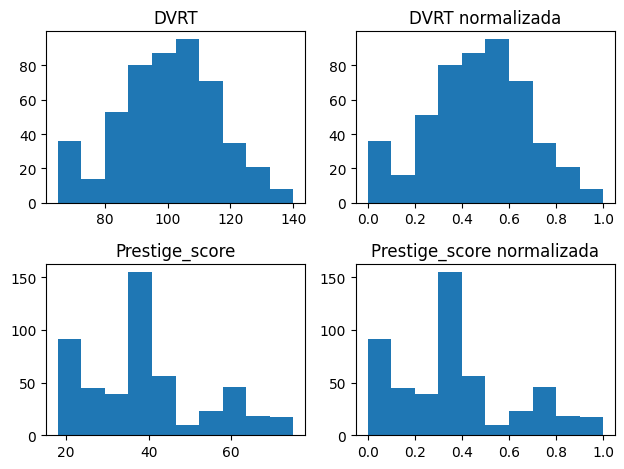

In [ ]:
# Comprobamos la nueva distribución vs la original
plt.subplot(2, 2, 1)#subgrafica(filas, columnas, indice/posicion)
plt.hist(data_transform['DVRT'])
plt.title('DVRT')

plt.subplot(2, 2, 2)
plt.hist(data_transform['DVRT_norm'])
plt.title('DVRT normalizada')

plt.subplot(2, 2, 3)
plt.hist(data_transform['Prestige_score'])
plt.title('Prestige_score')

plt.subplot(2, 2, 4)
plt.hist(data_transform['Prestige_score_norm'])
plt.title('Prestige_score normalizada')

plt.tight_layout()#reorganiza el espaciado, los margenes, etc para que nada se solape.
plt.show()

¡Y ya lo tenemos! Hemos procesado el conjunto de datos y lo hemos transformado en una serie de variables numéricas con las que entrenar nuestros algoritmos de aprendizaje automático.

Solo nos queda seleccionar las columnas numéricas que necesitamos y la variable objetivo.

In [ ]:
dataset = data_transform.select_dtypes(include = 'number').drop(['DVRT', 'Prestige_score'], axis = 1)
dataset

,target_num,Sex_num,Educational_level_3rd_level_complete,Educational_level_Junior_cycle_incomplete-secondary_school,Educational_level_Junior_cycle_incomplete-vocational_school,Educational_level_Junior_cycle_terminal_leaver-secondary_school,Educational_level_Junior_cycle_terminal_leaver-vocational_school,Educational_level_Primary_terminal_leaver,Educational_level_Senior_cycle_terminal_leaver-secondary_school,Educational_level_infrequent_sklearn,Type_school_primary_terminal_leaver,Type_school_secondary,Type_school_vocational,DVRT_norm,Prestige_score_norm
0,0.0,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.640000,0.175439
1,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.480000,0.175439
2,1.0,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.600000,0.894737
3,0.0,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.746667,0.684211
4,0.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.226667,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,1.0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.960000,0.771930
496,1.0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.946667,0.000000
497,1.0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.893333,0.333333
498,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.933333,0.771930


In [ ]:
# Extraer nueva matriz de correlación, una vez que todos los datos son numericos
dataset.corr()

,target_num,Sex_num,Educational_level_3rd_level_complete,Educational_level_Junior_cycle_incomplete-secondary_school,Educational_level_Junior_cycle_incomplete-vocational_school,Educational_level_Junior_cycle_terminal_leaver-secondary_school,Educational_level_Junior_cycle_terminal_leaver-vocational_school,Educational_level_Primary_terminal_leaver,Educational_level_Senior_cycle_terminal_leaver-secondary_school,Educational_level_infrequent_sklearn,Type_school_primary_terminal_leaver,Type_school_secondary,Type_school_vocational,DVRT_norm,Prestige_score_norm
target_num,1.000000,4.025327e-02,0.401404,-2.257698e-01,-0.297874,-0.345435,-0.354541,-0.252618,0.730361,-0.101191,-0.252618,0.596664,-0.488712,0.413265,0.309795
Sex_num,0.040253,1.000000e+00,-0.031465,-9.367295e-17,-0.040000,0.172463,-0.093352,-0.022921,0.051120,-0.094120,-0.022921,0.155146,-0.152120,-0.077457,-0.117322
Educational_level_3rd_level_complete,0.401404,-3.146522e-02,1.000000,-9.062484e-02,-0.119568,-0.138659,-0.142314,-0.101402,-0.250604,-0.089007,-0.101402,0.263216,-0.221473,0.351044,0.174492
Educational_level_Junior_cycle_incomplete-secondary_school,-0.225770,-9.367295e-17,-0.090625,1.000000e+00,-0.084215,-0.097662,-0.100236,-0.071420,-0.176508,-0.062690,-0.071420,0.185391,-0.155990,-0.025394,-0.063867
Educational_level_Junior_cycle_incomplete-vocational_school,-0.297874,-4.000000e-02,-0.119568,-8.421519e-02,1.000000,-0.128852,-0.132249,-0.094230,-0.232879,-0.082712,-0.094230,-0.454257,0.539875,-0.190231,-0.129600
Educational_level_Junior_cycle_terminal_leaver-secondary_school,-0.345435,1.724633e-01,-0.138659,-9.766158e-02,-0.128852,1.000000,-0.153364,-0.109275,-0.270063,-0.095918,-0.109275,0.283654,-0.238670,-0.049253,-0.050594
Educational_level_Junior_cycle_terminal_leaver-vocational_school,-0.354541,-9.335201e-02,-0.142314,-1.002361e-01,-0.132249,-0.153364,1.000000,-0.112156,-0.277182,-0.098447,-0.112156,-0.540674,0.642580,-0.132000,-0.111031
Educational_level_Primary_terminal_leaver,-0.252618,-2.292081e-02,-0.101402,-7.142036e-02,-0.094230,-0.109275,-0.112156,1.000000,-0.197498,-0.070145,1.000000,-0.385241,-0.174540,-0.329356,-0.167438
Educational_level_Senior_cycle_terminal_leaver-secondary_school,0.730361,5.111986e-02,-0.250604,-1.765078e-01,-0.232879,-0.270063,-0.277182,-0.197498,1.000000,-0.173357,-0.197498,0.450141,-0.364649,0.177969,0.192882
Educational_level_infrequent_sklearn,-0.101191,-9.412028e-02,-0.089007,-6.269028e-02,-0.082712,-0.095918,-0.098447,-0.070145,-0.173357,1.000000,-0.070145,-0.051126,0.095629,0.068487,0.029699


## 4. Didivir en conjunto de entrenamiento y conjunto de test

También hemos visto que es buena práctica reservar una porción del conjunto de datos para validar los modelos de aprendizaje automático. Esto es muy sencillo de hacer con sklearn.

In [ ]:
from sklearn.model_selection import train_test_split#dividir tus datos entre entrenamiento y test para ML

# Datos de entrenamieno y test - 80/20
X_train, X_test, y_train, y_test = train_test_split(
    dataset.drop('target_num', axis = 1),#Elimina la columna target_num del dataset de X.
    #Porque esa columna es el objetivo (y), no debe usarse como input (X).
    dataset['target_num'],#Extrae SOLO la columna target_num. Porque es la col que hay que predecir->entrenar
    test_size=0.2  #20% de los datos para el test
)
#train_test_split, devuelve 4 variables, 2train-> entrenar, 2test-> testear

print(X_train.shape, X_test.shape)

(400, 14) (100, 14)


## Conclusiones

En este cuaderno hemos analizado y preprocesado un conjunto de datos. Entender los datos nos ha permitido hacernos una mejor idea de la información y de la tarea a resolver, y el preprocesamiento permite depurar y mejorar la calidad de los registros. Con estas operaciones, ya estaríamos preparados para entrenar un algoritmo de aprendizaje automático para predecir si un alumno realizará el examen de acceso a la universidad o no.

En la próxima unidad, veremos cómo entrenar modelos utilizando sklearn.

## Ejercicios

  - Observando las variables disponibles en el conjunto de datos y la variable objetivo, ¿se te ocurre alguna otra variable que se podría añadir al dataset?

  - En este cuaderno hemos hecho una cosa de forma ligeramente incorrecta desde el punto de vista metodológico (a propósito, veremos en las próximas unidades cómo corregirlo). ¿Qué crees que puede ser, y por qué es incorrecto?